In [1]:
# 24I-6034   Hamza Faheem     DS-B     DAV LAB-04

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("food_delivery_orders.csv")
if 'order_date' in df.columns:
    df['order_date'] = pd.to_datetime(df['order_date'])

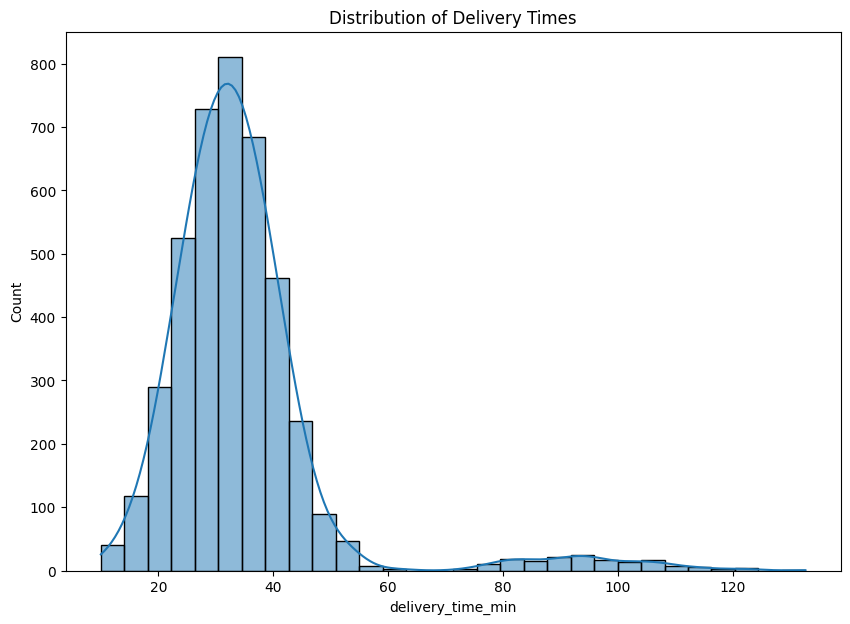

Skewness = 2.8770611473024483
Mean = 34.541809523809526
Median = 32.5


In [3]:
### TASK 1 ###
plt.figure(figsize = (10,7))
sns.histplot(df['delivery_time_min'], kde = True, bins = 30)
plt.title("Distribution of Delivery Times")
plt.show()

skewness = df['delivery_time_min'].skew()
meanTime = df['delivery_time_min'].mean()
medianTime = df['delivery_time_min'].median()

print(f"Skewness = {skewness}")
print(f"Mean = {meanTime}")
print(f"Median = {medianTime}")

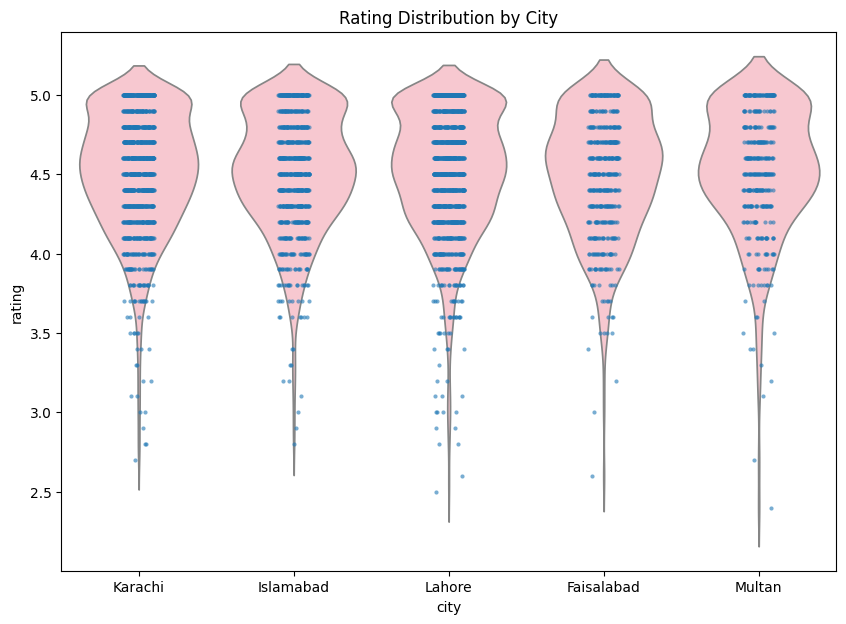

In [4]:
### TASK 2 ###
plt.figure(figsize = (10,7))
sns.violinplot(data = df, x = 'city', y = 'rating', color = 'pink', inner = None)
sns.stripplot(data = df, x = 'city', y = 'rating', jitter = True, size = 3, alpha = 0.6)
plt.title("Rating Distribution by City")
plt.show()


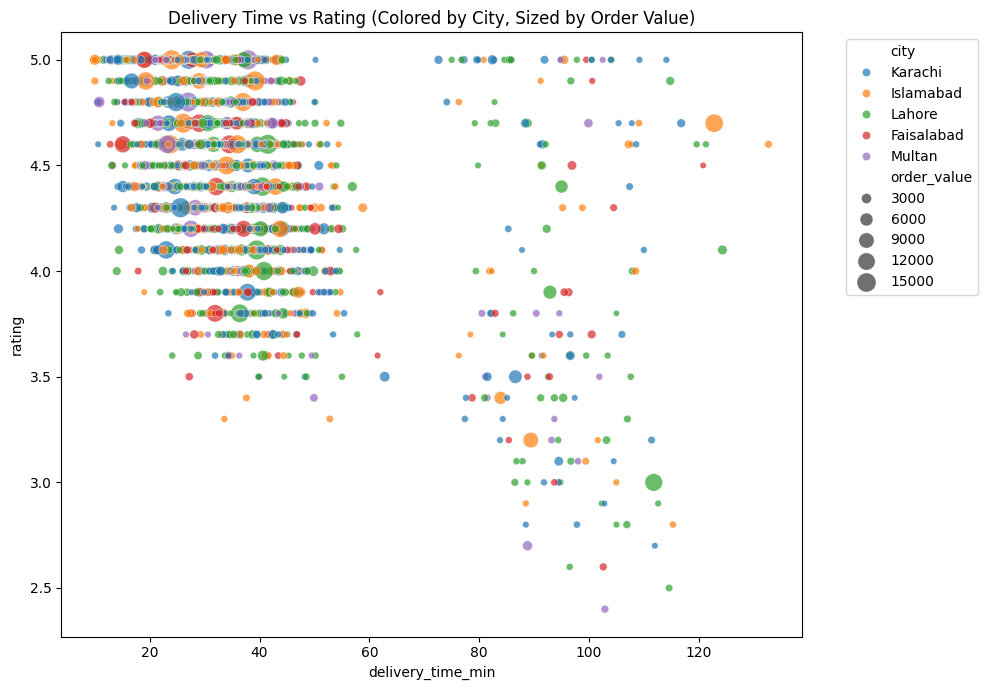

In [5]:
### TASK 3 ###
plt.figure(figsize = (10, 7))
sns.scatterplot(data = df, x = 'delivery_time_min', y = 'rating', hue = 'city', size = 'order_value', sizes = (20, 200), alpha = 0.7)
plt.title('Delivery Time vs Rating (Colored by City, Sized by Order Value)')
plt.legend(bbox_to_anchor = (1.05, 1), loc = 'upper left')
plt.tight_layout()
plt.show()

In [6]:
### TASK 4 ###
numeric_df = df.select_dtypes(include = [np.number])

pearson_corr = numeric_df.corr(method = 'pearson')
spearman_corr = numeric_df.corr(method = 'spearman')

diff_matrix = (pearson_corr - spearman_corr).abs()
print("Max disagreement between Pearson and Spearman ==>")
print(diff_matrix.unstack().sort_values(ascending = False).drop_duplicates().head(2))

Max disagreement between Pearson and Spearman ==>
order_value       profit_per_order    1.330259
discount_percent  profit_per_order    0.298532
dtype: float64


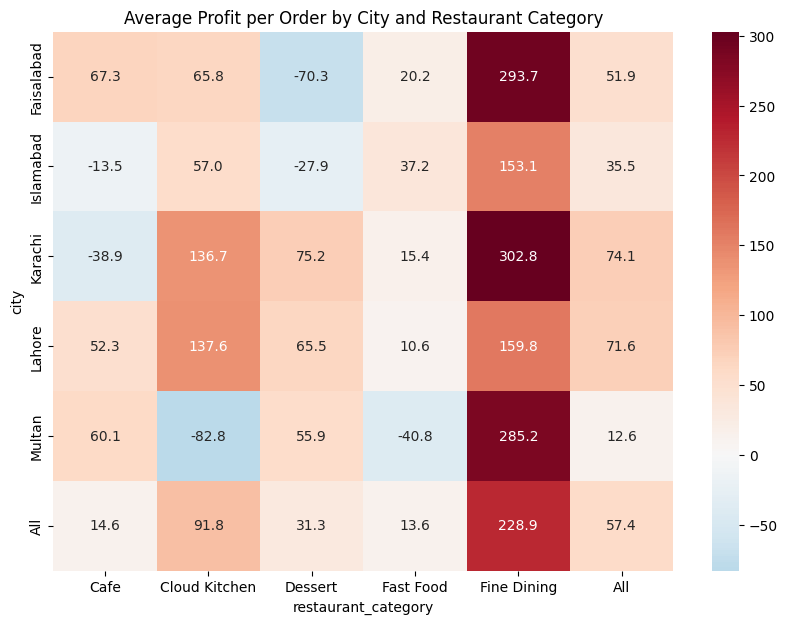

Max Profit Combo = 
 restaurant_category
Cafe    Faisalabad
dtype: object

Max Revenue Combo = 
 restaurant_category
Cafe    Karachi
dtype: object


In [7]:
### TASK 5 ###
pivotProfit = pd.pivot_table(df, values = 'profit_per_order', index = 'city', columns = 'restaurant_category', aggfunc = 'mean', margins = True)

plt.figure(figsize = (10, 7))
sns.heatmap(pivotProfit, annot = True, cmap = 'RdBu_r', center = 0, fmt = ".1f")
plt.title('Average Profit per Order by City and Restaurant Category')
plt.show()

pivot_rev = pd.pivot_table(df, values = 'order_value', index = 'city', columns = 'restaurant_category', aggfunc = 'mean', margins = True)
print("Max Profit Combo = \n", pivotProfit.drop('All', axis = 0).drop('All', axis = 1).idxmax().head(1))
print("\nMax Revenue Combo = \n", pivot_rev.drop('All', axis = 0).drop('All', axis = 1).idxmax().head(1))

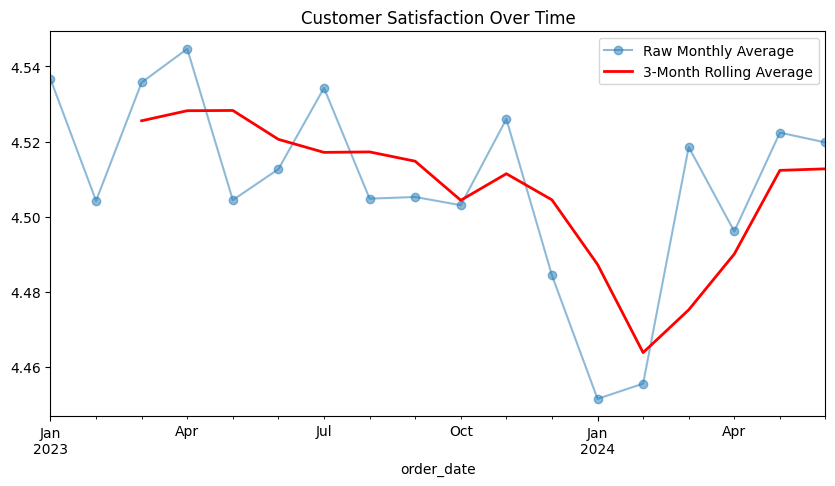

In [8]:
### TASK 6 ###
df_time = df.set_index('order_date').sort_index()
monthlyRating = df_time['rating'].resample('ME').mean()
rollingRating = monthlyRating.rolling(window = 3).mean()

plt.figure(figsize = (10, 5))
monthlyRating.plot(label = 'Raw Monthly Average', marker = 'o', alpha = 0.5)
rollingRating.plot(label = '3-Month Rolling Average', color = 'red', linewidth = 2)
plt.title('Customer Satisfaction Over Time')
plt.legend()
plt.show()

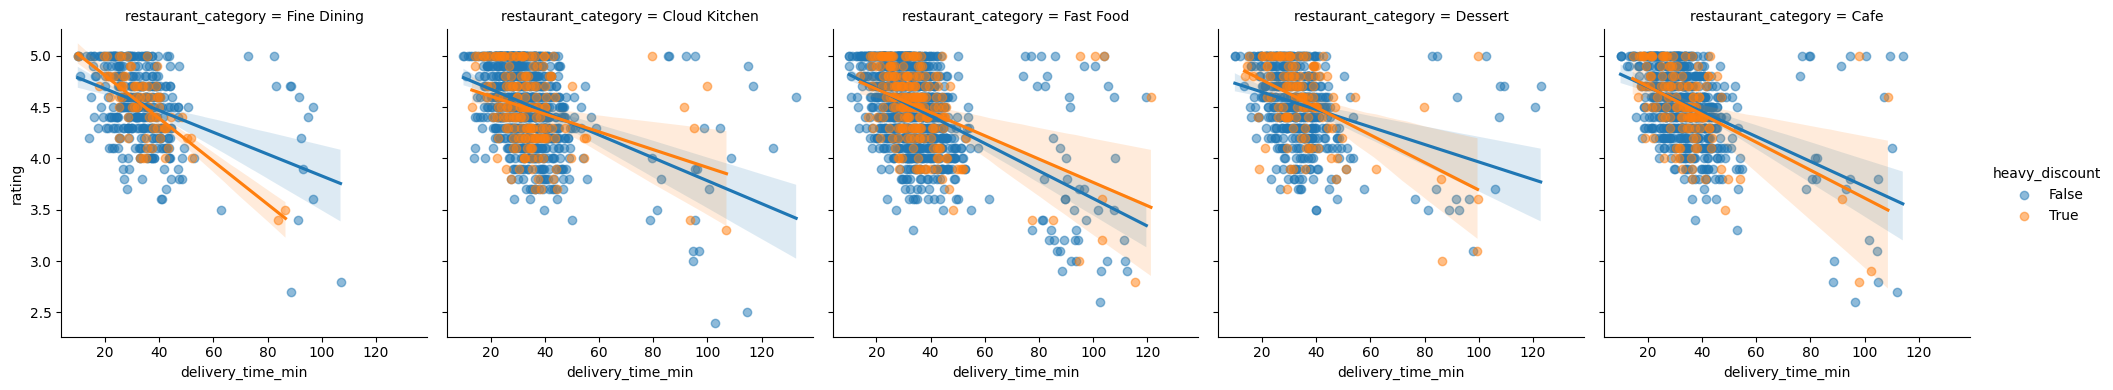

In [9]:
### TASK 7 ###
df['heavy_discount'] = df['discount_percent'] > 20

sns.lmplot(data = df, x = 'delivery_time_min', y = 'rating', col = 'restaurant_category', hue = 'heavy_discount', scatter_kws = {'alpha': 0.5}, height = 4, aspect = 1)
plt.show()

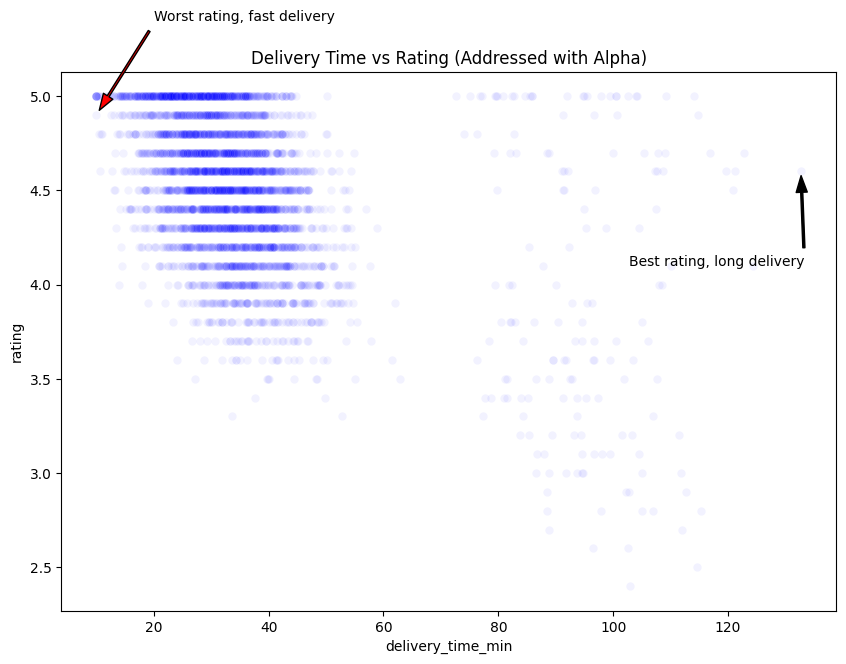

In [10]:
### TASK 8 ###
plt.figure(figsize = (10, 7))
sns.scatterplot(data = df, x = 'delivery_time_min', y = 'rating', alpha = 0.05, color = 'blue')

best_rating_slowest = df.sort_values(['delivery_time_min', 'rating'], ascending = [False, False]).iloc[0]
worst_rating_fastest = df.sort_values(['delivery_time_min', 'rating'], ascending = [True, True]).iloc[0]

plt.annotate('Best rating, long delivery', xy = (best_rating_slowest['delivery_time_min'], best_rating_slowest['rating']), xytext = (best_rating_slowest['delivery_time_min'] - 30, best_rating_slowest['rating'] - 0.5), arrowprops = dict(facecolor='black', shrink = 0.05, width = 1.5, headwidth = 8))
plt.annotate('Worst rating, fast delivery', xy = (worst_rating_fastest['delivery_time_min'], worst_rating_fastest['rating']), xytext = (worst_rating_fastest['delivery_time_min'] + 10, worst_rating_fastest['rating'] + 0.5), arrowprops = dict(facecolor = 'red', shrink = 0.05, width = 1.5, headwidth = 8))
plt.title('Delivery Time vs Rating (Addressed with Alpha)')
plt.show()